# Insurance Fraud Detection (Model Comparison)

**Goal:** Predict if an insurance claim is **fraud** (`Y`) or **genuine** (`N`), so investigators can check risky claims first.

**Why this matters:** Fraud costs insurance companies a lot of money. But checking every claim by hand is slow. A model can give each claim a *fraud score* and tell us which claims to check first.

**Steps**
1. Import libraries
2. Load data
3. Understand data
4. Clean data (the hidden `?` values)
5. Explore with charts
6. Feature engineering and dropping useless columns
7. Train/test split
8. Build the preprocessing pipeline
9. Compare 7 models
10. Tune the best model (XGBoost)
11. Choose a better decision threshold
12. Final test results
13. Important features
14. Save the model and predict a new claim

> Keep `Worksheet in Case Study question 2.xlsx` in the same folder. Install once: `pip install pandas numpy matplotlib seaborn scikit-learn xgboost openpyxl joblib`

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, cross_validate,
                                     cross_val_predict, StratifiedKFold, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve)

sns.set_style("whitegrid")

## Step 2: Load the data

In [2]:
FILE = "Worksheet in Case Study question 2.xlsx"
df = pd.read_excel(FILE)
df.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


## Step 3: Understand the data

Each row is **one insurance claim**. The target column is `fraud_reported` (Y = fraud, N = genuine).
Other columns describe the customer, the policy, the accident and the claim amounts.

In [3]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (1000, 39)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   months_as_customer           1000 non-null   int64         
 1   age                          1000 non-null   int64         
 2   policy_number                1000 non-null   int64         
 3   policy_bind_date             1000 non-null   datetime64[us]
 4   policy_state                 1000 non-null   str           
 5   policy_csl                   1000 non-null   str           
 6   policy_deductable            1000 non-null   int64         
 7   policy_annual_premium        1000 non-null   float64       
 8   umbrella_limit               1000 non-null   int64         
 9   insured_zip                  1000 non-null   int64         
 10  insured_sex                  1000 non-null   str           
 11  insured_education_level   

## Step 4: Clean the data

Two hidden problems exist in this dataset:

1. **`?` values.** In `collision_type`, `property_damage` and `police_report_available`, missing information is written as `?`. Pandas does not see `?` as missing. We keep it as its own category called "unknown", because *not knowing* can itself be a useful signal.
2. **`authorities_contacted`.** Pandas read the text `"None"` as a missing value. It really means "no authority was contacted", so we fill it back with the word `"None"`.

In [4]:
print("Real missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
for col in ["collision_type", "property_damage", "police_report_available"]:
    print(col, "->", (df[col] == "?").sum(), "rows with '?'")
print("Duplicate rows:", df.duplicated().sum())

Real missing values:
authorities_contacted    91
dtype: int64

collision_type -> 178 rows with '?'
property_damage -> 360 rows with '?'
police_report_available -> 343 rows with '?'
Duplicate rows: 0


In [5]:
df["authorities_contacted"] = df["authorities_contacted"].fillna("None")
df = df.replace("?", "Unknown")      # keep '?' as a real category
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## Step 5: Explore the data (EDA)

### 5.1 How many frauds?

fraud_reported
N    753
Y    247
Name: count, dtype: int64
fraud_reported
N    75.3
Y    24.7
Name: proportion, dtype: float64


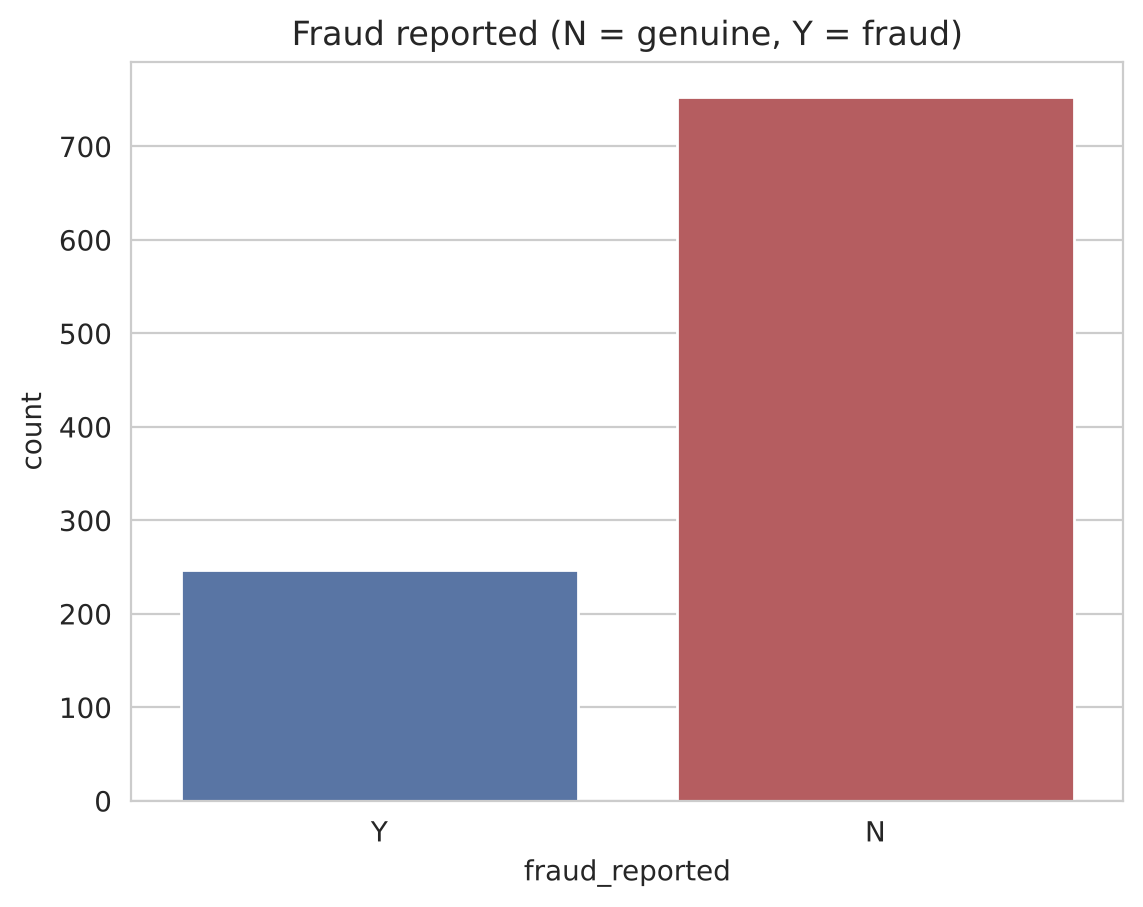

In [6]:
print(df["fraud_reported"].value_counts())
print((df["fraud_reported"].value_counts(normalize=True) * 100).round(1))

sns.countplot(x="fraud_reported", data=df, palette=["#4c72b0", "#c44e52"])
plt.title("Fraud reported (N = genuine, Y = fraud)")
plt.show()

About **25%** of claims are fraud. This is *moderately imbalanced*: not as extreme as 3%, but accuracy alone can still hide mistakes. We will focus on **recall, F1 and ROC-AUC** too.

### 5.2 Fraud rate by incident severity

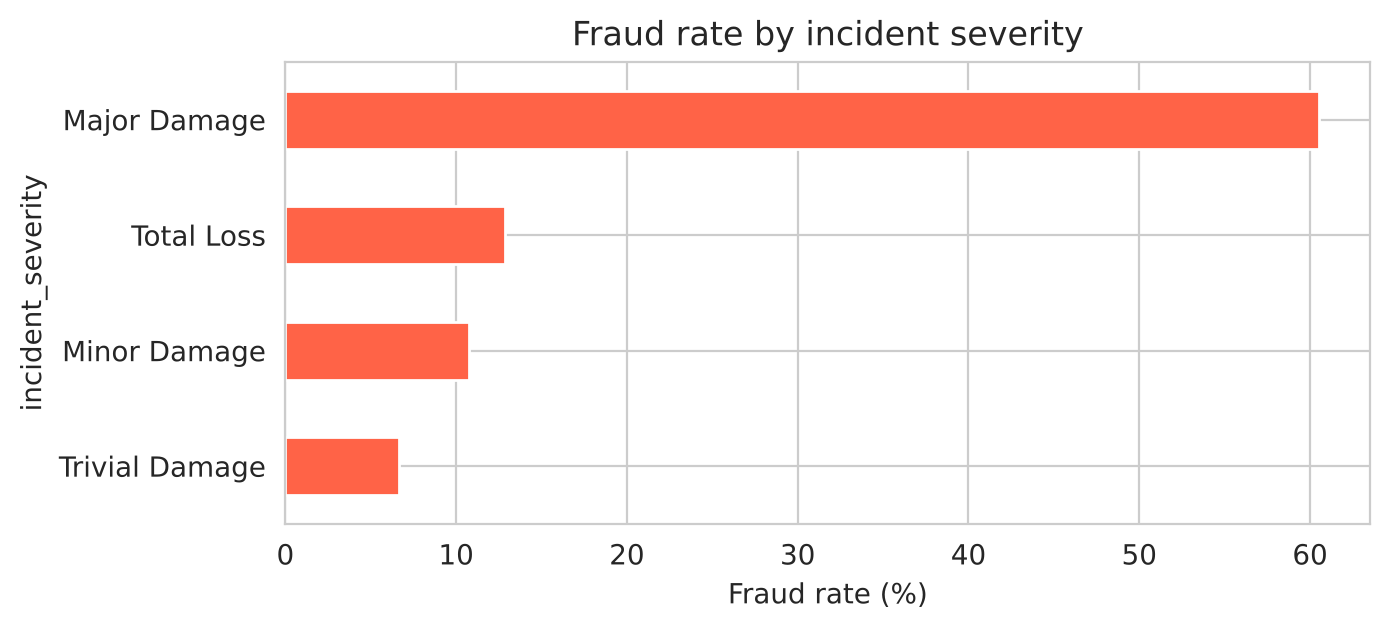

In [7]:
df["is_fraud"] = (df["fraud_reported"] == "Y").astype(int)

rate = df.groupby("incident_severity")["is_fraud"].mean().sort_values() * 100
rate.plot(kind="barh", color="tomato", figsize=(7, 3))
plt.xlabel("Fraud rate (%)")
plt.title("Fraud rate by incident severity")
plt.show()

Claims with **Major Damage** are fraud far more often than other claims. This will be a strong feature.

### 5.3 Fraud rate by hobby

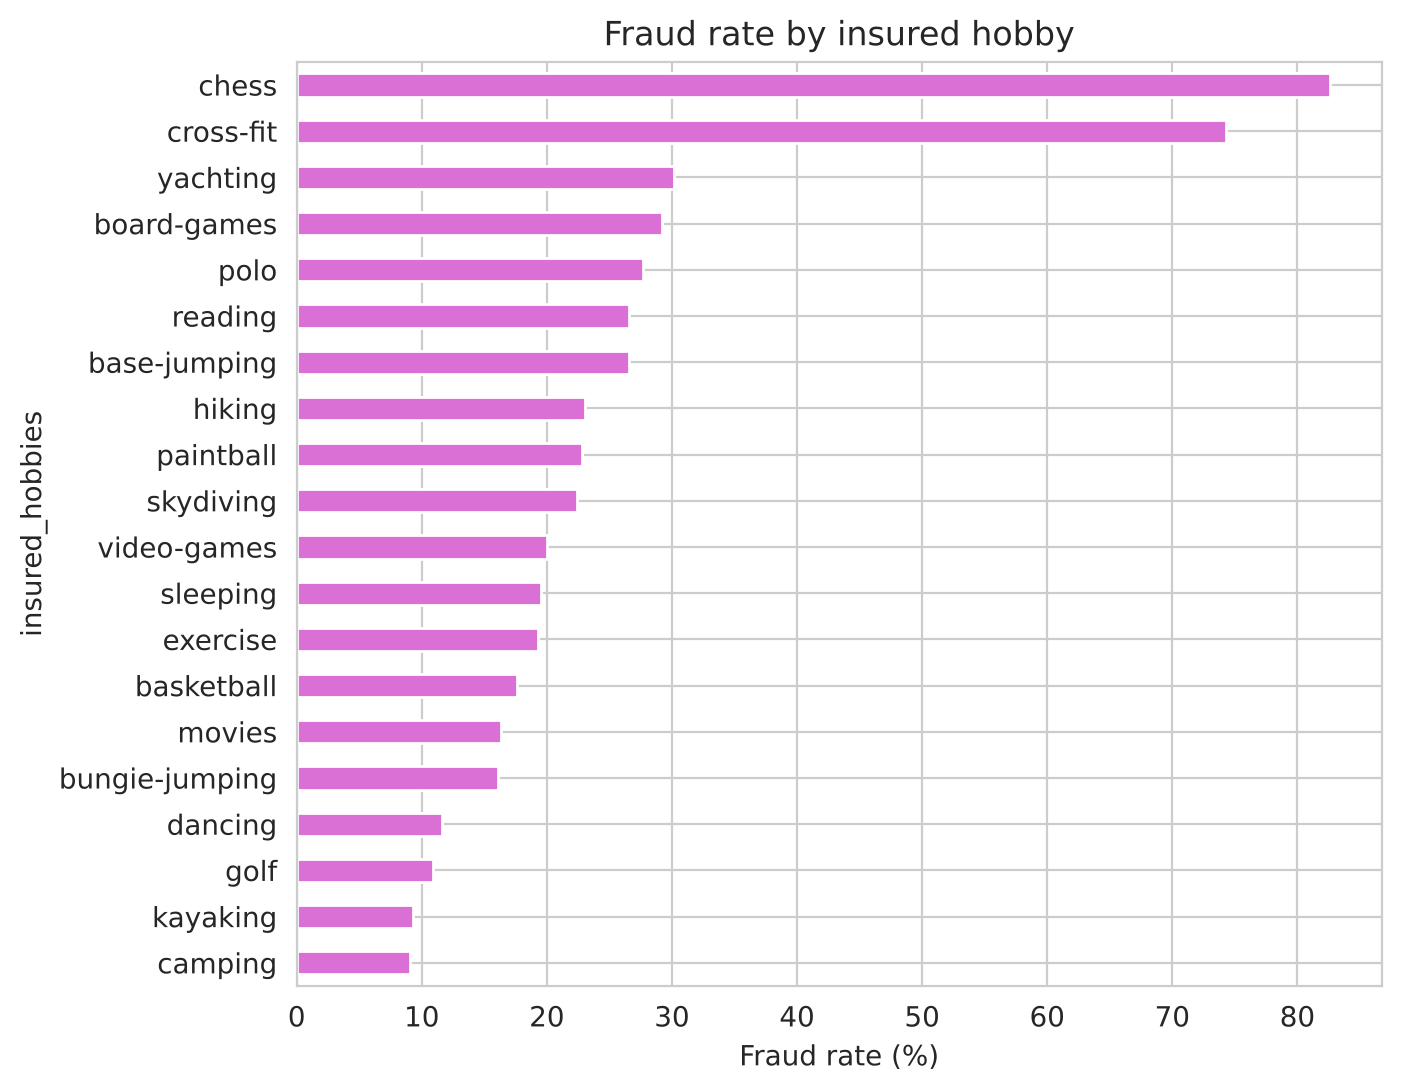

In [8]:
rate = df.groupby("insured_hobbies")["is_fraud"].mean().sort_values() * 100
rate.plot(kind="barh", color="orchid", figsize=(7, 6))
plt.xlabel("Fraud rate (%)")
plt.title("Fraud rate by insured hobby")
plt.show()

Two hobbies, **chess** and **cross-fit**, have a much higher fraud rate. The model can use this pattern.

### 5.4 Claim amounts: fraud vs genuine

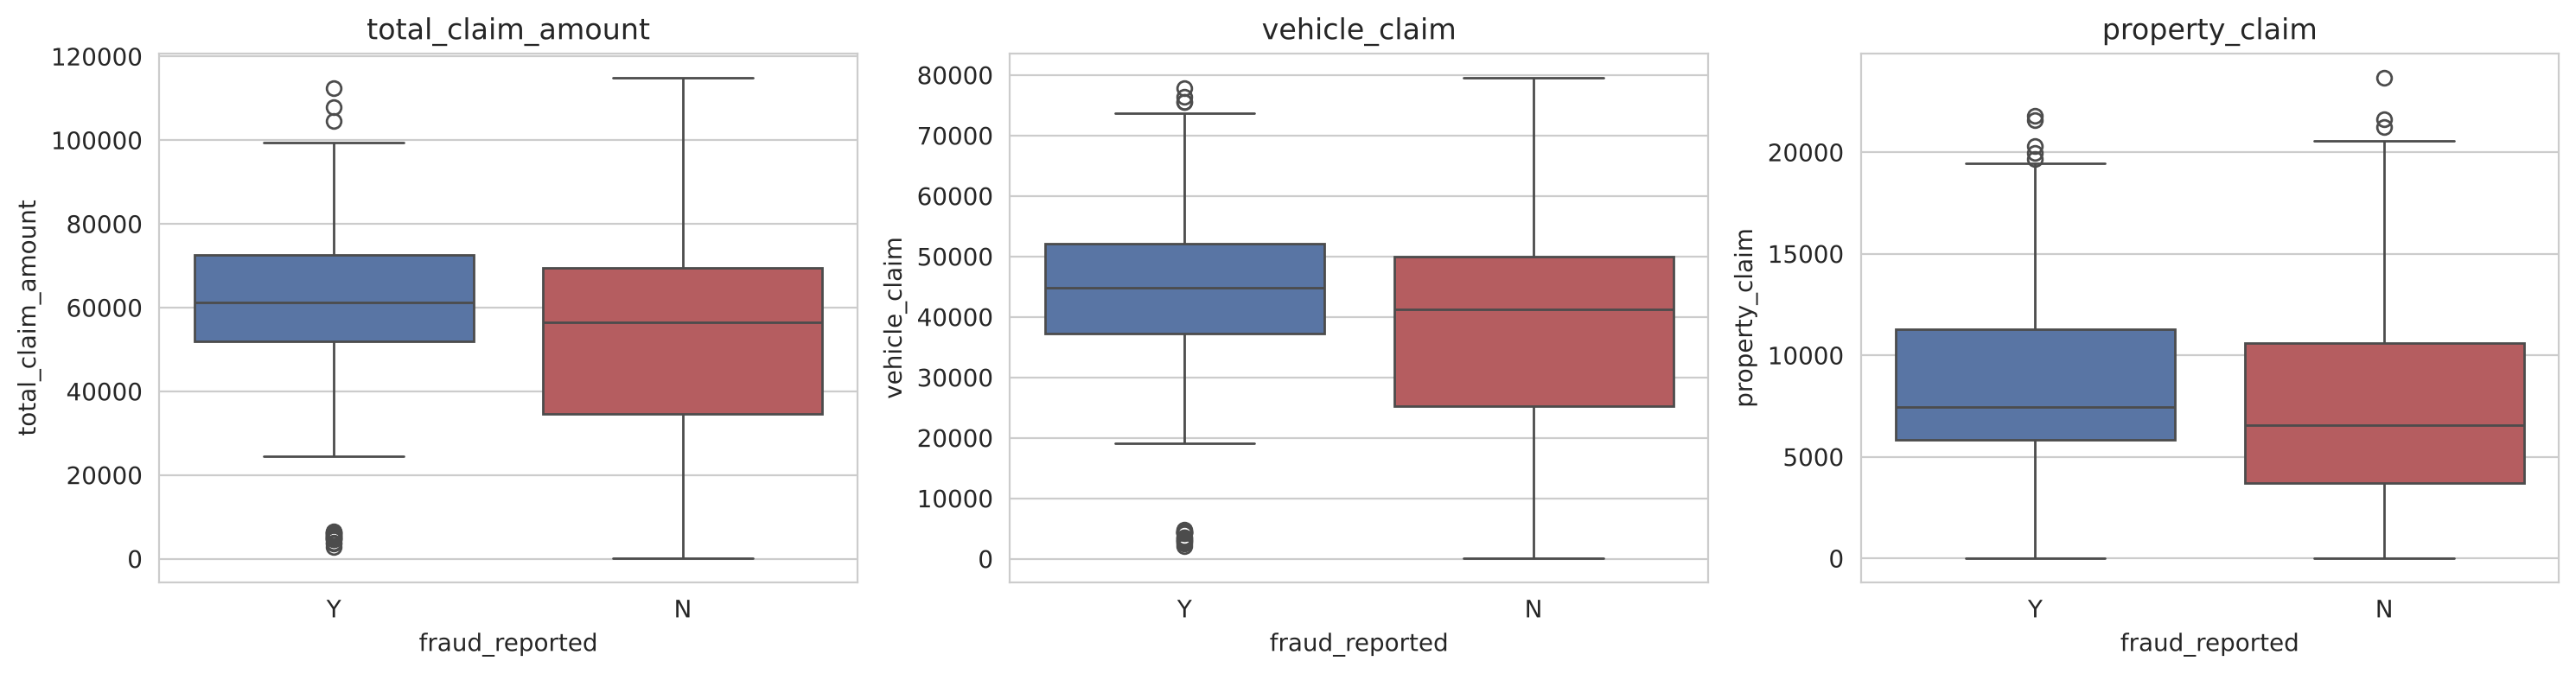

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["total_claim_amount", "vehicle_claim", "property_claim"]):
    sns.boxplot(x="fraud_reported", y=col, data=df, ax=ax, palette=["#4c72b0", "#c44e52"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 5.5 Correlation of number columns

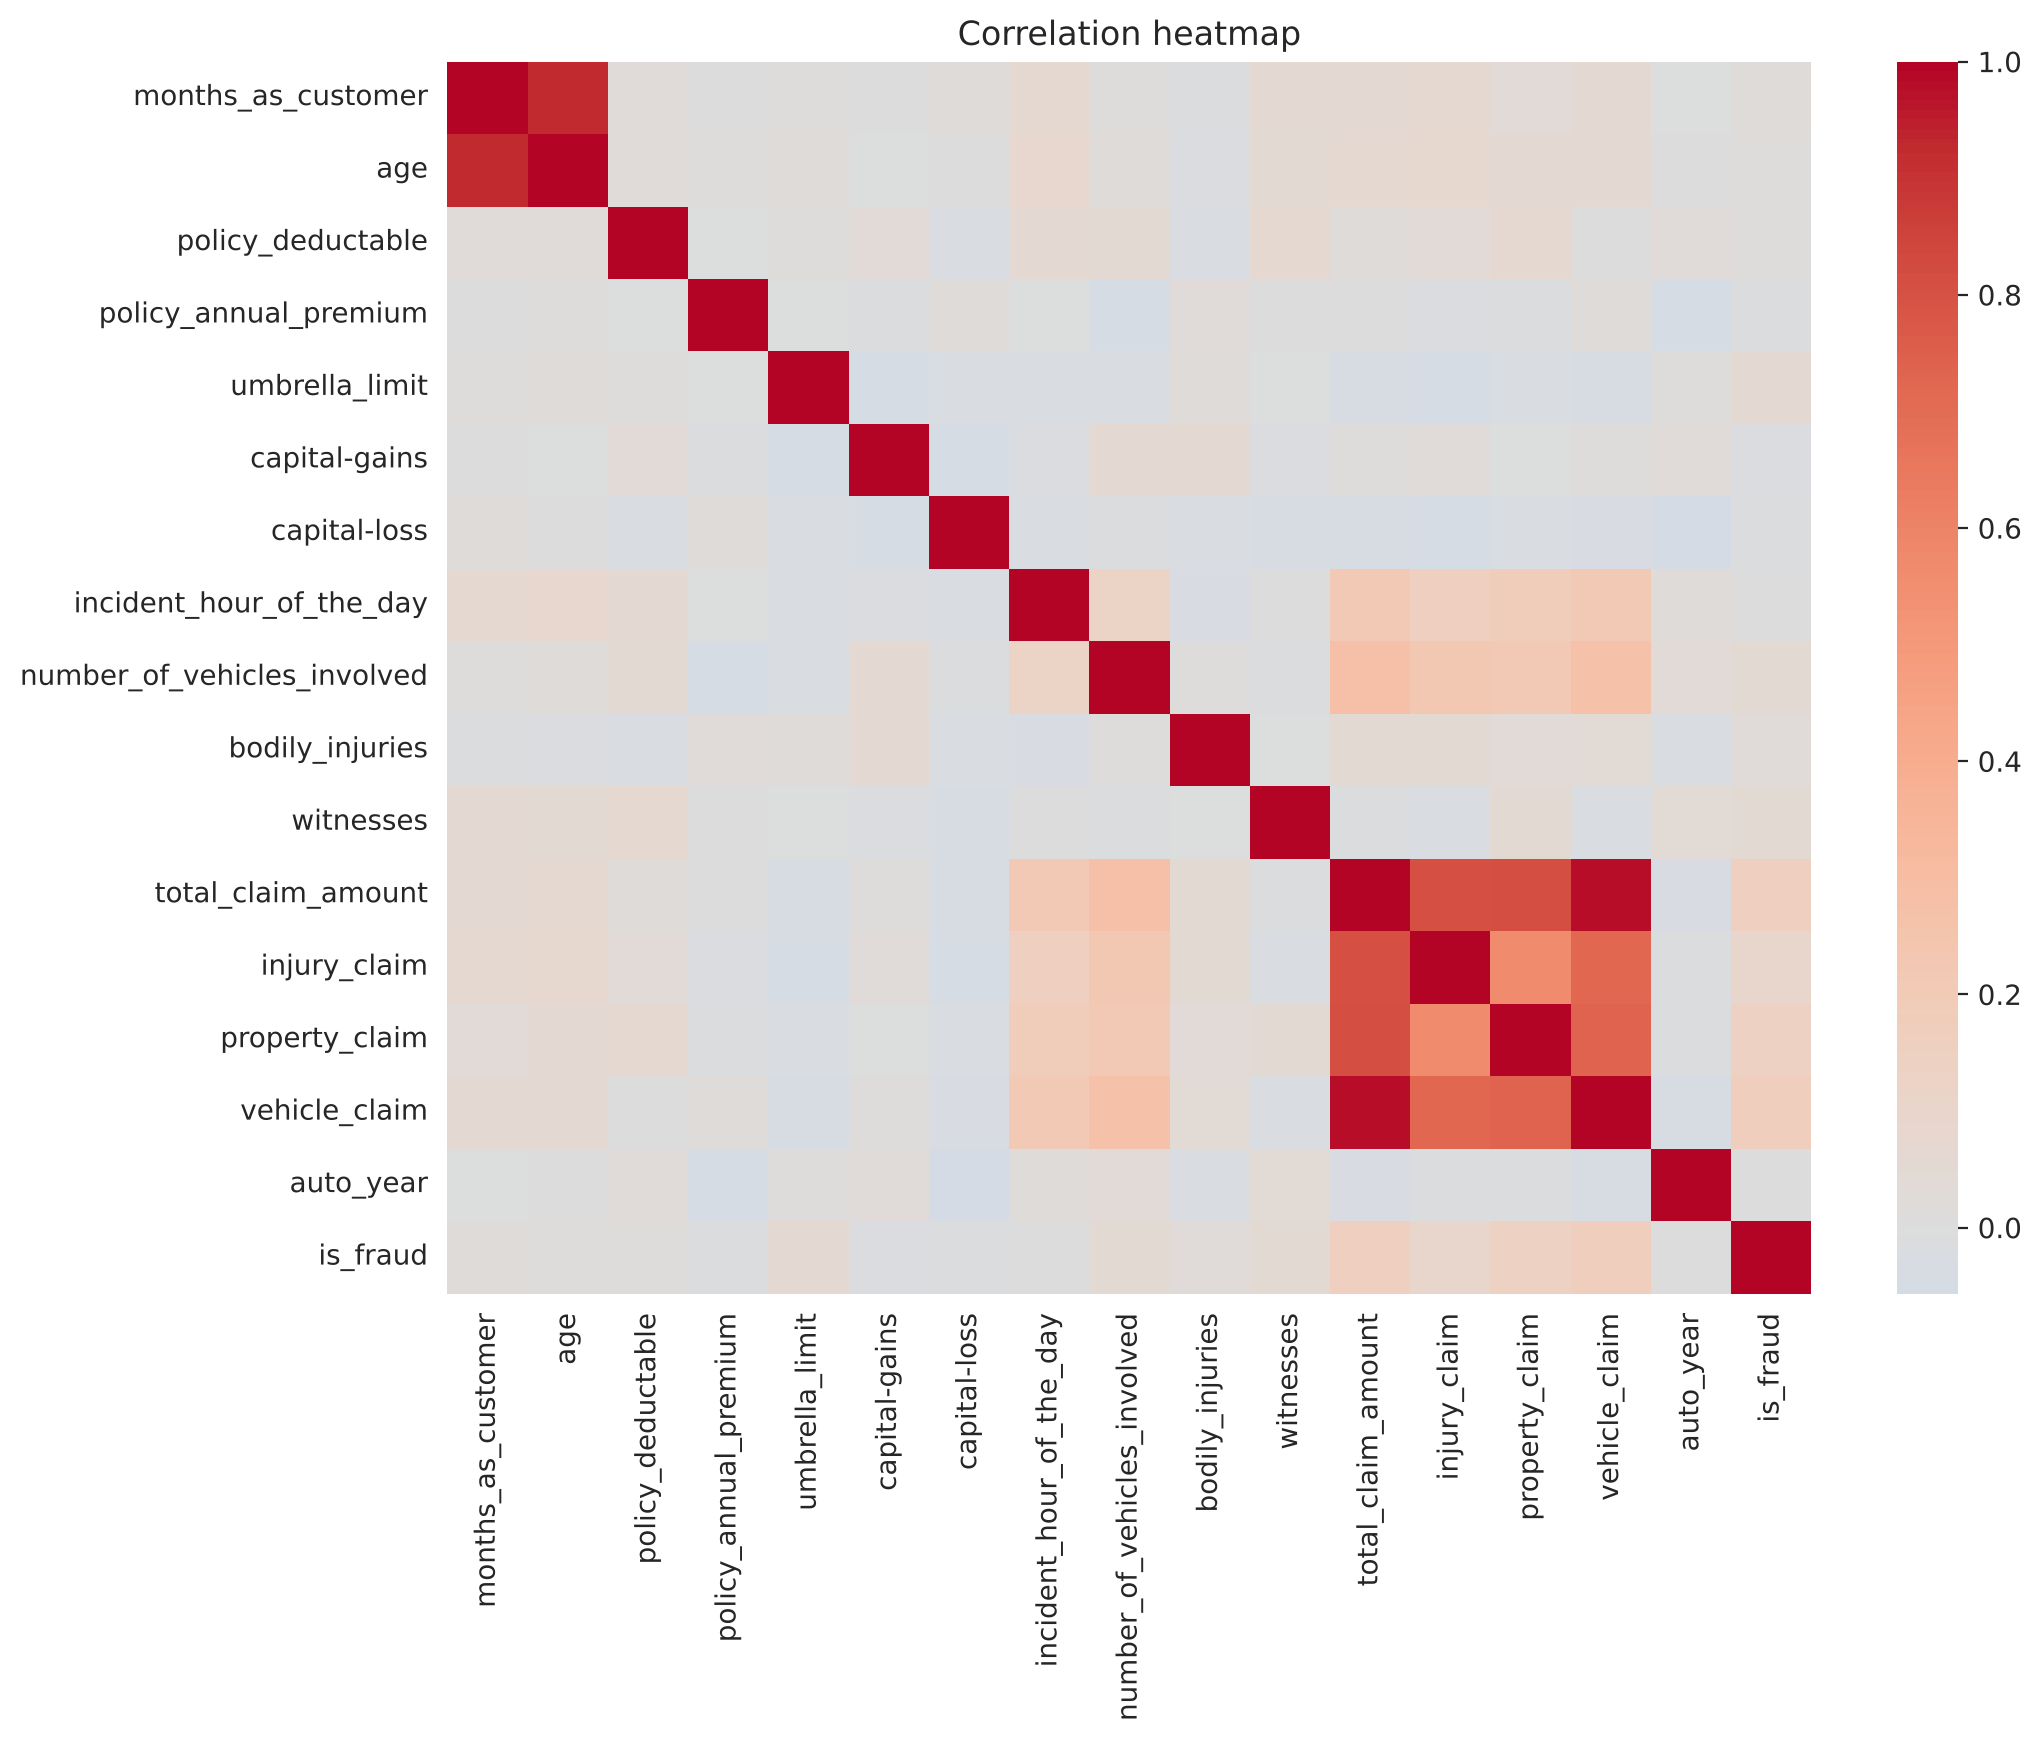

In [10]:
num_cols = df.select_dtypes(include="number").columns.drop(
    ["policy_number", "insured_zip"], errors="ignore")
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap")
plt.show()

`total_claim_amount` is the sum of `injury_claim`, `property_claim` and `vehicle_claim`, so they move together. `age` and `months_as_customer` are also strongly related.

## Step 6: Feature engineering and dropping useless columns

**Create 2 new features**
- `policy_age_days`: days between policy start and the accident. A claim very soon after buying a policy can look suspicious.
- `vehicle_age`: age of the car at the time of the accident (data is from 2015).

**Drop columns that do not help**
- `policy_number`, `insured_zip`, `incident_location`: ID-like values, almost unique for every row.
- `auto_model`: 39 different values for only 1000 rows, so it adds mostly noise (we keep `auto_make`).
- `policy_bind_date`, `incident_date`, `auto_year`: already converted into the new features.
- `is_fraud`: the helper column we made for charts (it is the answer, so it must not be a feature).

In [11]:
df["policy_age_days"] = (df["incident_date"] - df["policy_bind_date"]).dt.days
df["vehicle_age"] = 2015 - df["auto_year"]

y = df["is_fraud"]
X = df.drop(columns=["fraud_reported", "is_fraud", "policy_number", "insured_zip",
                     "incident_location", "auto_model", "policy_bind_date",
                     "incident_date", "auto_year"])
print("Features:", X.shape[1])

Features: 33


## Step 7: Train/test split

80% for training, 20% hidden for the final test. `stratify=y` keeps the fraud ratio the same in both parts.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Fraud % train:", round(y_train.mean() * 100, 1), "| test:", round(y_test.mean() * 100, 1))

Train: (800, 33)  Test: (200, 33)
Fraud % train: 24.8 | test: 24.5


## Step 8: Preprocessing pipeline

Models need numbers, but many columns are text. We prepare each type:
- **Number columns** -> `StandardScaler` (put all numbers on a similar scale)
- **Text columns** -> `OneHotEncoder` (turn each category into a 0/1 column)

We put this inside a **Pipeline**. The pipeline learns the scaling only from training data, so no information leaks from the test data.

In [13]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(len(num_cols), "number columns,", len(cat_cols), "text columns")

preprocess = ColumnTransformer([
    ("numbers", StandardScaler(), num_cols),
    ("text", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

17 number columns, 16 text columns


## Step 9: Compare 7 models

| Model | Idea |
|---|---|
| Logistic Regression | Simple straight-line model, a good baseline |
| KNN | Looks at the most similar past claims |
| SVM | Draws the best boundary between fraud and genuine |
| Decision Tree | Asks yes/no questions |
| Random Forest | Many trees voting together |
| Gradient Boosting | Trees built one after another, each fixing the last one's mistakes |
| XGBoost | A faster, stronger version of gradient boosting |

**Fair comparison:** every model gets the *same* preprocessing and the same 5-fold cross-validation on the training data. For imbalance we use class weights where the model supports it.

In [14]:
# ratio used by XGBoost to give more importance to the fraud class
weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(class_weight="balanced", probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             scale_pos_weight=weight, random_state=42, eval_metric="logloss"),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name,
                 "Accuracy": s["test_accuracy"].mean(),
                 "Precision": s["test_precision"].mean(),
                 "Recall": s["test_recall"].mean(),
                 "F1": s["test_f1"].mean(),
                 "ROC-AUC": s["test_roc_auc"].mean()})

cv_results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("F1", ascending=False)
cv_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost,0.845,0.651,0.818,0.724,0.858
Decision Tree,0.839,0.646,0.783,0.706,0.788
Logistic Regression,0.831,0.635,0.778,0.697,0.864
Gradient Boosting,0.831,0.663,0.672,0.665,0.856
SVM,0.806,0.605,0.652,0.626,0.822
Random Forest,0.774,0.602,0.298,0.395,0.846
KNN,0.736,0.410,0.142,0.207,0.603


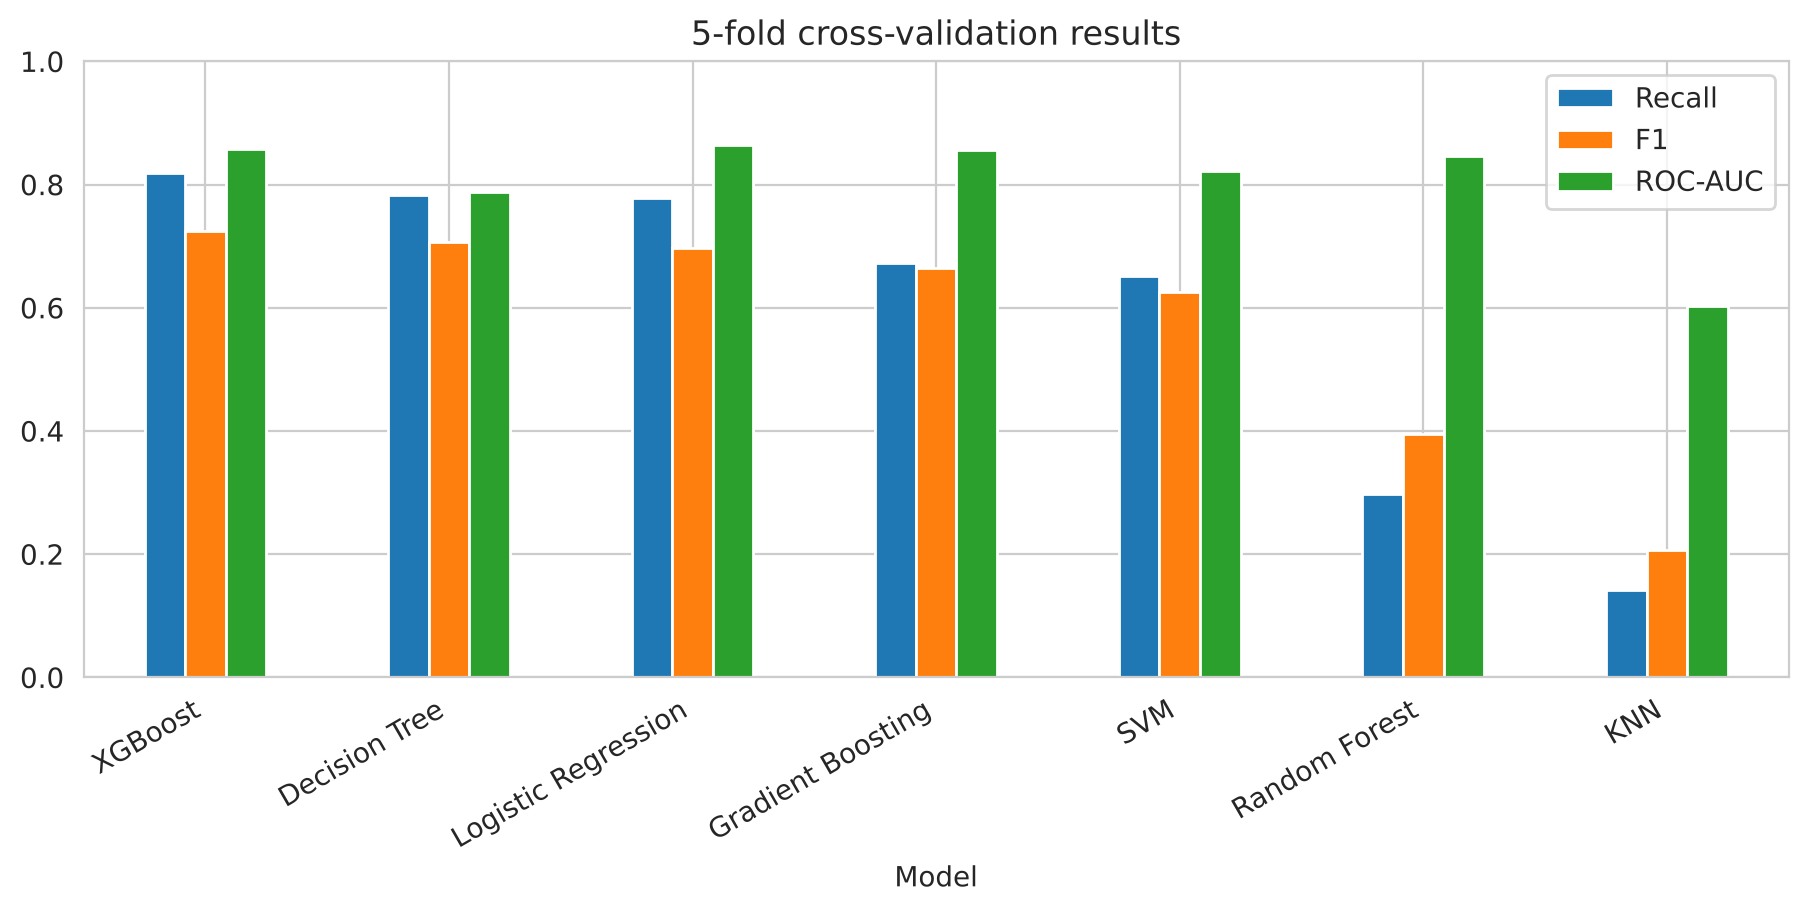

In [15]:
cv_results[["Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(11, 4))
plt.title("5-fold cross-validation results")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.show()

**How to read it**
- **Recall:** out of all real frauds, how many did we catch?
- **Precision:** out of all claims we flagged, how many were really fraud?
- **F1:** balance of precision and recall.
- **ROC-AUC:** how well the model ranks fraud above genuine claims (0.5 = random, 1.0 = perfect).

**What we learn:** KNN is clearly the weakest. Random Forest has good ROC-AUC but very low recall at the default 0.5 cutoff (we fix this cutoff in Step 11). Logistic Regression, Gradient Boosting and **XGBoost** are the strongest on ROC-AUC, and XGBoost has the best F1. Boosting models are also the best at learning complex patterns, so we tune **XGBoost** next.

## Step 10: Tune the best model (XGBoost)

Every model has settings called *hyperparameters*. `GridSearchCV` tries many combinations with cross-validation and keeps the best one. We score by ROC-AUC.

In [16]:
xgb_pipe = Pipeline([
    ("prep", preprocess),
    ("model", XGBClassifier(scale_pos_weight=weight, random_state=42, eval_metric="logloss")),
])

param_grid = {
    "model__n_estimators": [100, 200, 300],     # number of trees
    "model__max_depth": [2, 3, 4],              # how deep each tree can grow
    "model__learning_rate": [0.03, 0.05, 0.1],  # how fast the model learns
}

grid = GridSearchCV(xgb_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings :", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best settings : {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 100}
Best CV ROC-AUC: 0.866


## Step 11: Choose a better decision threshold

By default a model says "fraud" when the probability is 0.5 or more. For fraud detection, **missing a fraud is worse than a false alarm**, so a lower cutoff can be better.

We find the best cutoff using *cross-validated predictions on the training data only*. We never look at the test data to choose it.

Best threshold: 0.31


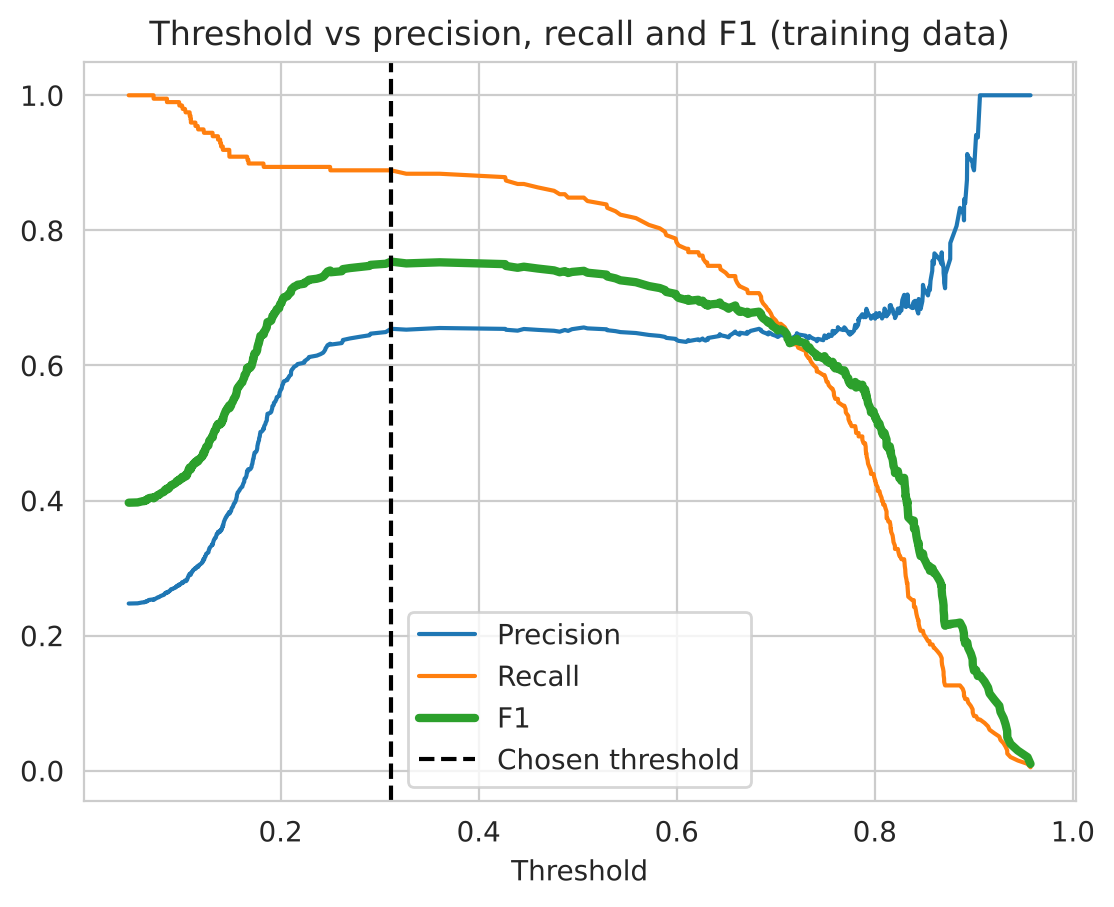

In [17]:
# probability of fraud for every training row, predicted by models that did NOT see that row
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
print("Best threshold:", round(best_threshold, 2))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores[:-1], label="F1", linewidth=3)
plt.axvline(best_threshold, color="black", linestyle="--", label="Chosen threshold")
plt.xlabel("Threshold")
plt.title("Threshold vs precision, recall and F1 (training data)")
plt.legend()
plt.show()

## Step 12: Final test results

Now we use the **hidden test data** for the first time. We compare all models on the same test set.
For the tuned XGBoost we show two rows: the default cutoff (0.5) and our chosen cutoff.

In [18]:
def score_row(name, y_true, y_pred, y_proba):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_proba)}

test_rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    test_rows.append(score_row(name, y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]))

# tuned XGBoost with default cutoff and with the chosen cutoff
proba_test = best_model.predict_proba(X_test)[:, 1]
test_rows.append(score_row("XGBoost (tuned, cutoff 0.5)", y_test, (proba_test >= 0.5).astype(int), proba_test))
test_rows.append(score_row("XGBoost (tuned, best cutoff)", y_test, (proba_test >= best_threshold).astype(int), proba_test))

test_results = pd.DataFrame(test_rows).set_index("Model").round(3).sort_values("F1", ascending=False)
test_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
"XGBoost (tuned, best cutoff)",0.845,0.636,0.857,0.730,0.836
"XGBoost (tuned, cutoff 0.5)",0.825,0.613,0.776,0.685,0.836
Logistic Regression,0.825,0.625,0.714,0.667,0.835
SVM,0.820,0.610,0.735,0.667,0.855
XGBoost,0.820,0.610,0.735,0.667,0.834
Decision Tree,0.820,0.614,0.714,0.660,0.711
Gradient Boosting,0.795,0.583,0.571,0.577,0.833
Random Forest,0.775,0.577,0.306,0.400,0.853
KNN,0.755,0.500,0.204,0.290,0.654


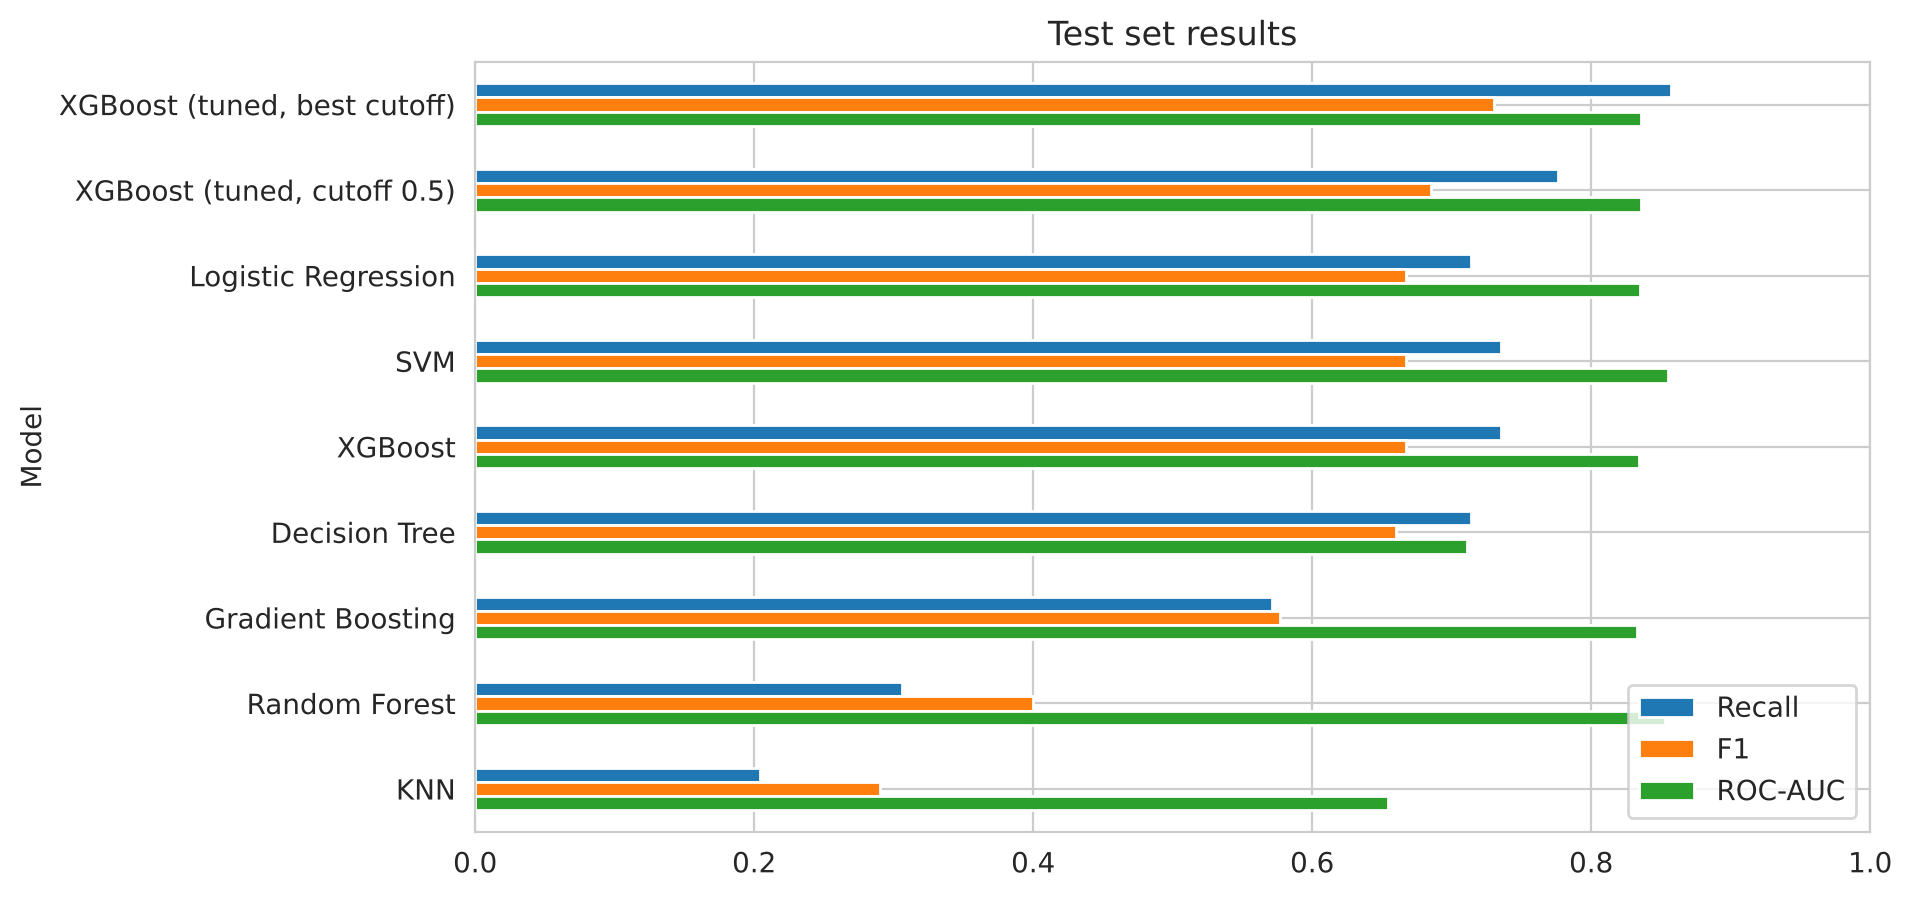

In [19]:
test_results[["Recall", "F1", "ROC-AUC"]].plot(kind="barh", figsize=(9, 5))
plt.title("Test set results")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.show()

**Note:** the test set is small (200 claims, about 49 frauds), so one or two claims can change a score a little. That is why we also looked at cross-validation in Step 9. Do not read small differences between models as real.

### Detailed report and confusion matrix of the final model

              precision    recall  f1-score   support

     Genuine       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200



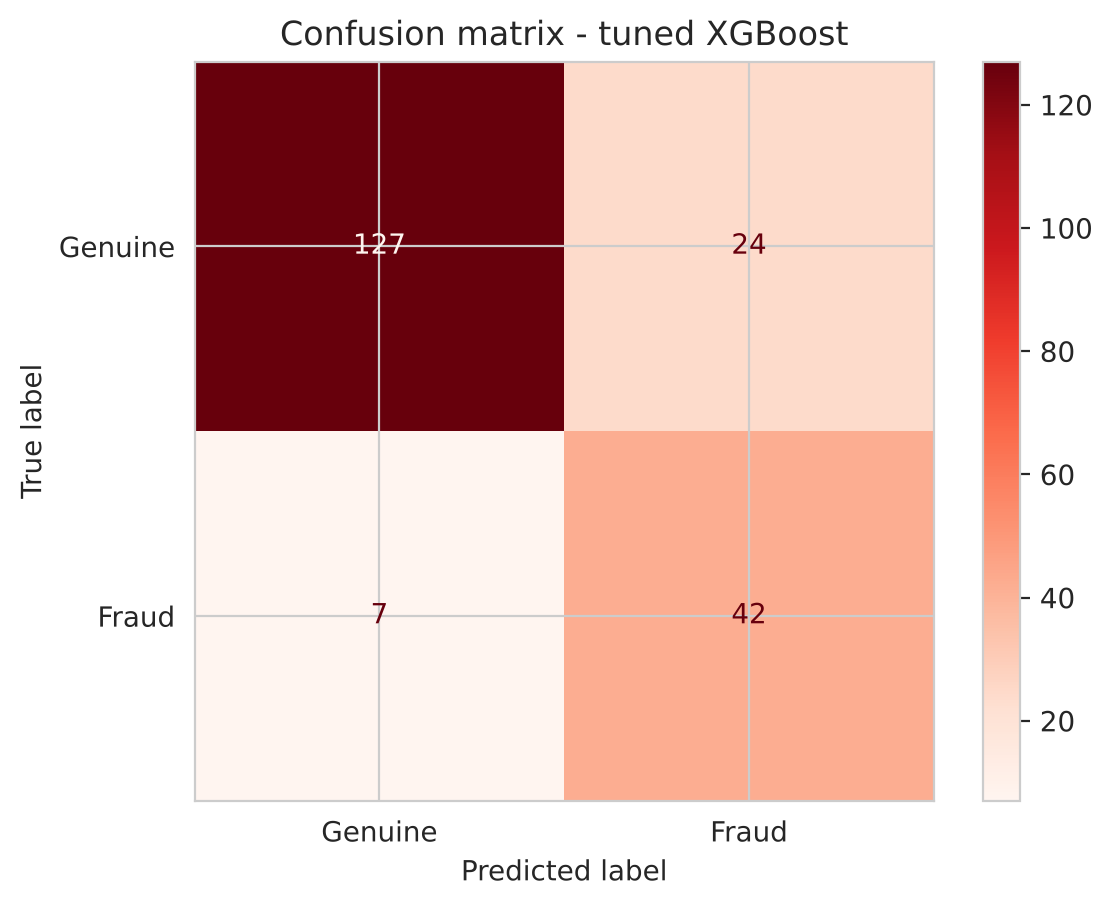

Frauds caught (TP)          : 42
Frauds missed (FN)          : 7   <- costly mistake
False alarms (FP)           : 24   <- extra checking work
Genuine claims passed (TN)  : 127


In [20]:
final_pred = (proba_test >= best_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=["Genuine", "Fraud"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred, display_labels=["Genuine", "Fraud"], cmap="Reds")
plt.title("Confusion matrix - tuned XGBoost")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, final_pred).ravel()
print(f"Frauds caught (TP)          : {tp}")
print(f"Frauds missed (FN)          : {fn}   <- costly mistake")
print(f"False alarms (FP)           : {fp}   <- extra checking work")
print(f"Genuine claims passed (TN)  : {tn}")

### ROC curves of the main models

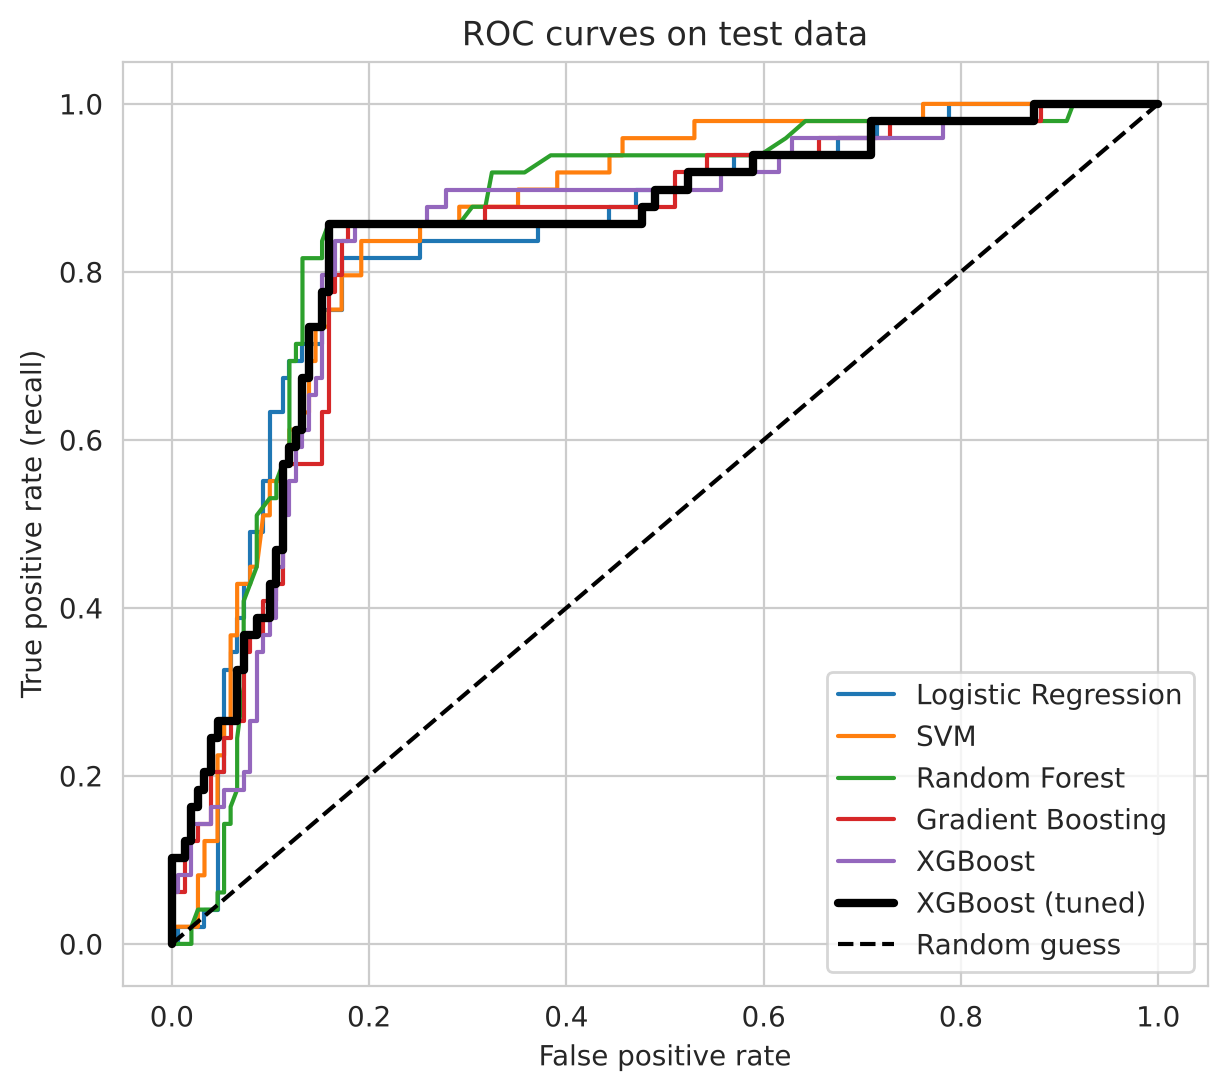

In [21]:
plt.figure(figsize=(7, 6))
for name in ["Logistic Regression", "SVM", "Random Forest", "Gradient Boosting", "XGBoost"]:
    pipe = Pipeline([("prep", preprocess), ("model", models[name])]).fit(X_train, y_train)
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)

fpr, tpr, _ = roc_curve(y_test, proba_test)
plt.plot(fpr, tpr, label="XGBoost (tuned)", linewidth=3, color="black")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on test data")
plt.legend()
plt.show()

## Step 13: Which features matter most?

This tells us what the model uses to find fraud. It is useful to explain the result to investigators.

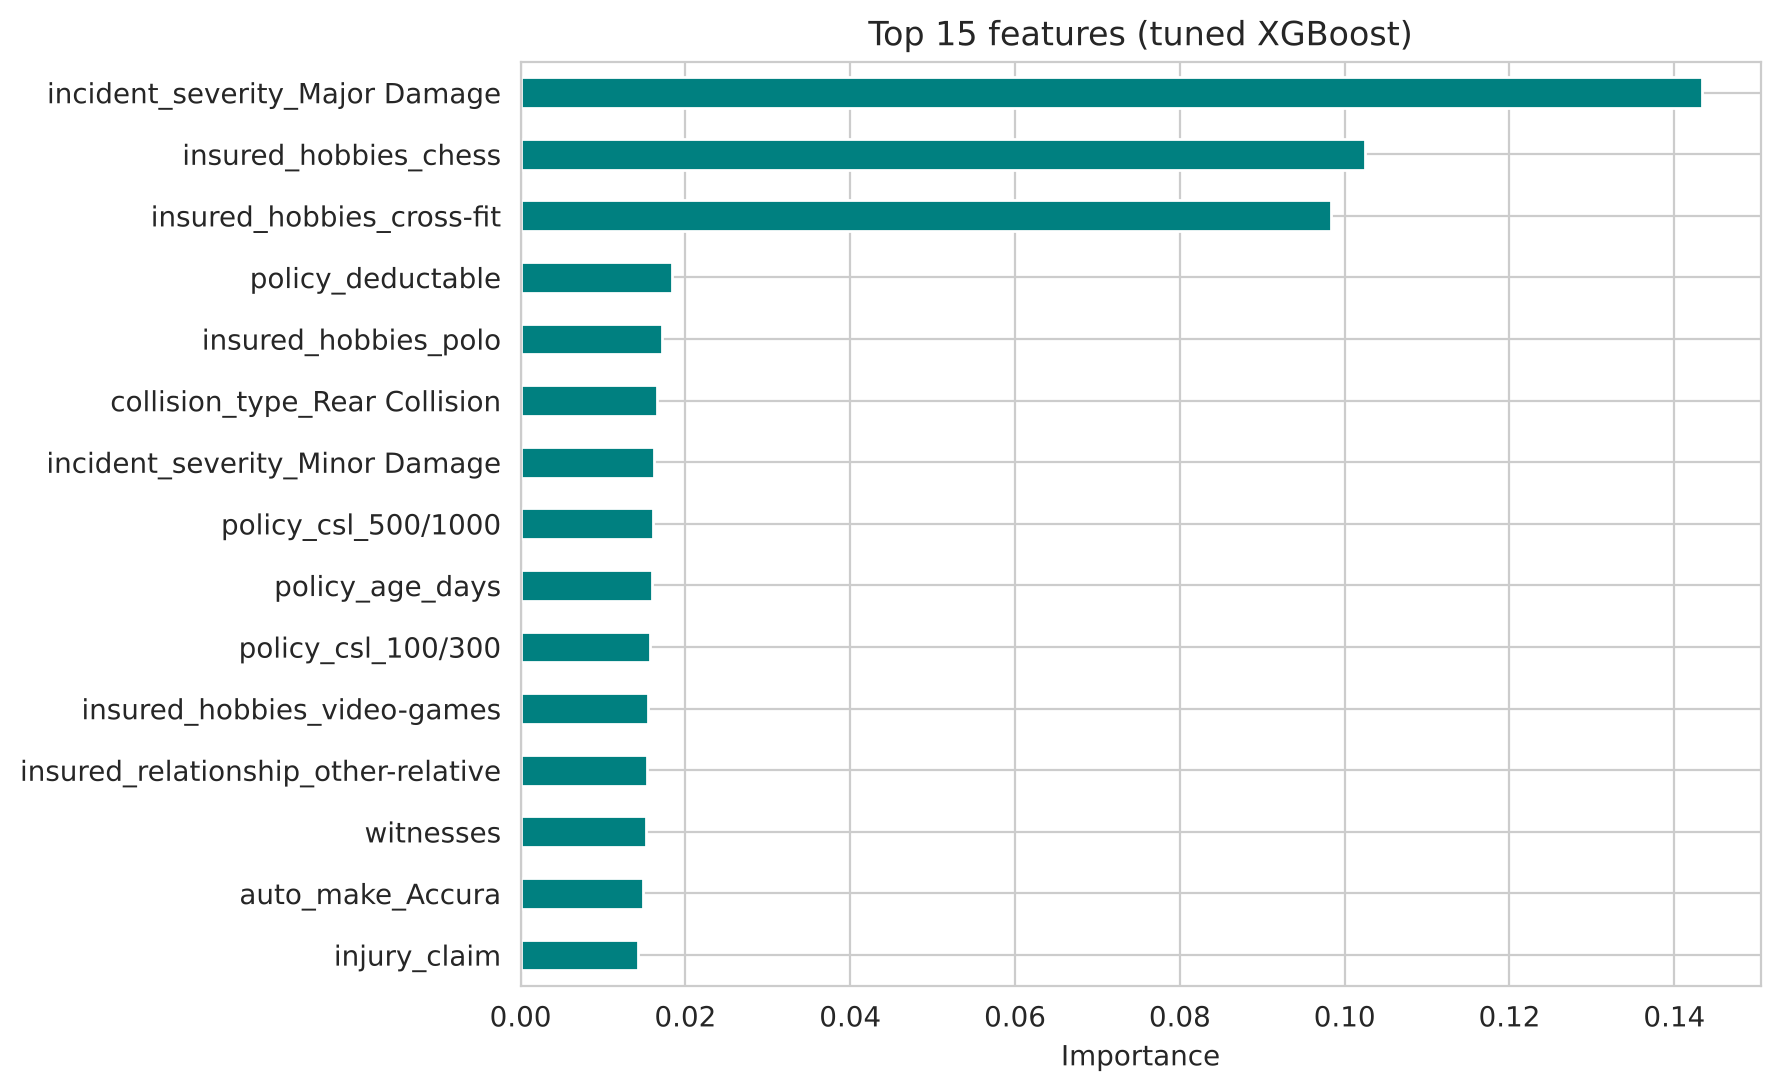

In [22]:
names = best_model.named_steps["prep"].get_feature_names_out()
names = [n.replace("numbers__", "").replace("text__", "") for n in names]
importance = pd.Series(best_model.named_steps["model"].feature_importances_, index=names)

importance.sort_values().tail(15).plot(kind="barh", figsize=(8, 6), color="teal")
plt.title("Top 15 features (tuned XGBoost)")
plt.xlabel("Importance")
plt.show()

`incident_severity` (Major Damage) and the hobbies **chess** and **cross-fit** are the top signals, which matches what we saw in the charts in Step 5.

## Step 14: Save the model and predict a new claim

We save the whole pipeline (preprocessing + model) and the threshold in one file. Then a function takes a new claim and returns a fraud score.

In [23]:
joblib.dump({"model": best_model, "threshold": best_threshold, "columns": X.columns.tolist()},
            "fraud_model.pkl")
print("Saved as fraud_model.pkl")

Saved as fraud_model.pkl


In [24]:
def predict_claim(claim: dict):
    saved = joblib.load("fraud_model.pkl")
    row = pd.DataFrame([claim])[saved["columns"]]          # same column order as training
    prob = saved["model"].predict_proba(row)[0, 1]
    label = "SUSPICIOUS - send to investigator" if prob >= saved["threshold"] else "Looks genuine"
    return label, f"{prob * 100:.1f}% fraud score"

# take 2 real rows from the test set as examples (one genuine, one fraud)
example_genuine = X_test[y_test == 0].iloc[0].to_dict()
example_fraud = X_test[y_test == 1].iloc[0].to_dict()

print("Actual: genuine ->", predict_claim(example_genuine))
print("Actual: fraud   ->", predict_claim(example_fraud))

Actual: genuine -> ('Looks genuine', '8.7% fraud score')
Actual: fraud   -> ('SUSPICIOUS - send to investigator', '77.2% fraud score')


## Summary

- The data has 1,000 claims with about **25% fraud**.
- We fixed hidden problems: `?` values were kept as an "Unknown" category, and `"None"` in `authorities_contacted` was restored.
- We built 2 new features (`policy_age_days`, `vehicle_age`) and removed ID-like columns.
- A **Pipeline** kept preprocessing safe from data leakage.
- We compared **7 models** with 5-fold cross-validation, then tuned **XGBoost** and chose a better decision threshold using training data only.
- Most important signals: **major damage** and the hobbies **chess / cross-fit**.

**Ideas to improve further**
- Try LightGBM or CatBoost.
- Use SMOTE on the training data only.
- Collect more data. 1,000 rows is small, so scores change a lot between splits.
- Build a Streamlit app where an investigator enters a claim and sees the fraud score.